# Convergenza: Fitness classica vs Extended Fitness

Dati da `notebooks/data_generation/convergence.ipynb`. Colore = risoluzione, stile = algoritmo (continua: Extended Fitness, tratteggiata: Fitness).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path

ROOT = next(p for p in [Path().resolve(), *Path().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

from src.plotting import set_style, figsize, HALF, PALETTE, save_fig, two_part_legend

set_style()
RES = ROOT / "results" / "convergenza"
PLOTS = ROOT / "plots" / "convergenza"

tables = {res: pd.read_parquet(RES / f"convergenza_{res}_digits.parquet") for res in (4, 6)}
STYLES = {"extended_fitness": ("-", "Extended Fitness"), "fitness": ("--", "Fitness")}

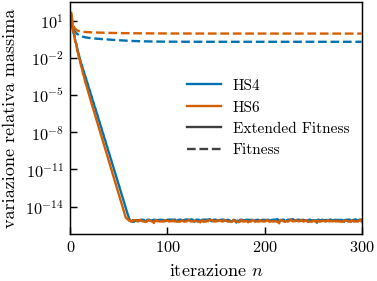

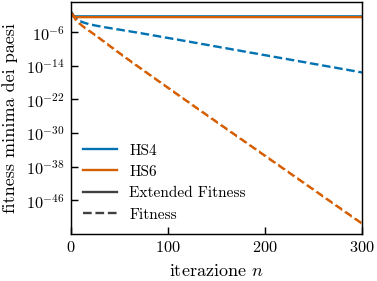

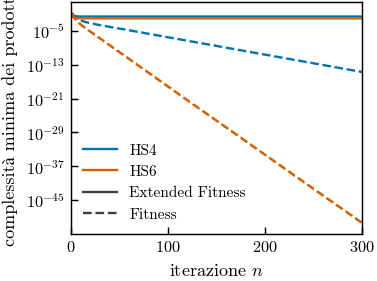

In [2]:
def plot_vs_iter(column, ylabel, save_name, legend_loc):
    fig, ax = plt.subplots(figsize=figsize(*HALF))
    for res, df in tables.items():
        for algo, (ls, _) in STYLES.items():
            d = df[df.algoritmo == algo]
            ax.plot(d["iter"], d[column], ls=ls, color=PALETTE[res])
    ax.set_yscale("log")
    ax.set_xlabel("iterazione $n$")
    ax.set_ylabel(ylabel)
    ax.set_xlim(0, tables[4]["iter"].max())
    two_part_legend(ax, [("HS4", PALETTE[4]), ("HS6", PALETTE[6])],
                    [(lab, ls, True) for ls, lab in STYLES.values()], loc=legend_loc)
    save_fig(fig, PLOTS / save_name)
    plt.show()


plot_vs_iter("dmax", "variazione relativa massima", "variazione_relativa", "center right")
plot_vs_iter("minF", "fitness minima dei paesi", "minimo_F", "lower left")
plot_vs_iter("minQ", "complessità minima dei prodotti", "minimo_Q", "lower left")